In [36]:
# ======================================================
# IMPORTS
# ======================================================

import json
import numpy as np
import pandas as pd
import xml.etree.ElementTree as ET
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.colorbar as mcolorbar
import matplotlib.axes as maxes
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D
import matplotlib.animation as animation
import matplotlib.lines as mlines
from matplotlib.ticker import MultipleLocator

In [37]:
# ======================================================
# CONFIG
# ======================================================

BASE_DIR = Path(
    r"C:\\SDU Courses\\Sem 4\\Thesis\\Sample data from DBU"
)

MATCH_FOLDERS = [
    "2025-08-23 F.C. København - OB (2558994)",
]

# ======================================================
# MODEL PARAMETERS
# ======================================================

# Pressing-run detection
MIN_SPEED              = 3.0   # m/s
ANGLE_THRESHOLD        = 0.4   # cos(60°) — minimum alignment toward target
SPEED_FRAMES_REQUIRED  = 3     # consecutive frames above MIN_SPEED to establish speed gate
ANGLE_BUFFER_FRAMES    = 3     # frames for angle smoothing
CLOSING_WINDOW_FRAMES  = 40    # frames over which closing distance is measured (~0.4s)
MIN_DIST_CLOSED        = 7   # meters — minimum closing distance over window
MIN_RUN_FRAMES         = 8     # frames all 3 gates must be satisfied to confirm a run (~0.32s)
RUN_BREAK_TOLERANCE    = 5     # frames a defender can fail gates before run breaks (~0.2s)
MAX_DIST_BALL          = 5.0   # meters — proximity threshold for sequence validity
NEXT_CARRIER_LOOKAHEAD = 50    # frames to look ahead for anticipated recipient (~2s)

# Ball control
MAX_CONTROL_DIST      = 2.0   # meters
MAX_CONTROL_HEIGHT    = 1.0   # meters
MIN_CONTROL_FRAMES    = 5     # ~0.2 seconds

# Pressing context
MAX_BALL_HEIGHT       = 1.0   # meters — pressable ball threshold
PRESSING_ZONE        = 45    # meters — last 35m of pitch
RECENT_AERIAL_FRAMES  = 10    # ~0.4 seconds

# Press sequence logic
NO_PRESS_TIMEOUT        = 3.5                           # seconds
PASS_GRACE_FRAMES       = 90                            # max frames to freeze timeout during ground pass transit (~2s)

# Forward pass termination
FORWARD_PASS_THRESHOLD  = 10.0  # meters

# ETSY Synchronization
ETSY_SEARCH_WINDOW  = 2.0   # seconds either side of event timestamp to search
ETSY_ACCEL_WINDOW   = 5     # frames for smoothing acceleration signal

In [38]:
# ======================================================
# EVENT MAP
# ======================================================

event_map = {
    1: "Pass",
    2: "Offside pass",
    3: "Take on",
    4: "Foul",
    5: "Out",
    6: "Corner awarded",
    7: "Tackle",
    8: "Interception",
    10: "Save",
    11: "Claim",
    12: "Clearance",
    13: "Missed shot",
    14: "Shot saved",
    15: "Shot blocked",
    16: "Goal",
    17: "Card",
    18: "Player off",
    19: "Player on",
    27: "Start delay",
    28: "End delay",
    30: "End",
    32: "Start",
    34: "Team setup",
    37: "Player changed position",
    40: "Formation change",
    41: "Punch",
    43: "Good skill",
    44: "Aerial",
    45: "Challenge",
    49: "Ball recovery",
    50: "Dispossessed",
    52: "Keeper pickup",
    54: "Touch",
    55: "Offside provoked",
    59: "Corner taken",
    61: "Ball touch",
    68: "Throw-in",
    70: "Goal kick",
    74: "Block",
    81: "Shield ball",
    83: "Attempted tackle"
}

In [39]:
# ======================================================
# LOAD FUNCTIONS
# ======================================================

def load_tracking(match_dir):
    tracking_file = list(match_dir.glob("*SecondSpectrum_Data.jsonl"))[0]

    rows = []
    with open(tracking_file, "r", encoding="utf-8") as f:
        for line in f:
            rows.append(json.loads(line))

    return pd.json_normalize(rows)

def load_metadata(match_dir):
    meta_file = list(match_dir.glob("*Metadata.json"))[0]
    with open(meta_file, "r", encoding="utf-8") as f:
        meta = json.load(f)
    return {
        "pitch_length": meta["pitchLength"],
        "pitch_width":  meta["pitchWidth"],
        "fps":          meta["fps"],
        "periods":      meta["periods"]      # ← add this
    }


def load_events(match_dir):
    event_file = list(match_dir.glob("*eventdetails.xml"))[0]
    tree       = ET.parse(event_file)
    root       = tree.getroot()

    events = []
    for event in root.iter("Event"):
        attrib     = dict(event.attrib)

        # Parse qualifiers
        qualifiers = {q.attrib["qualifier_id"]: q.attrib.get("value", True)
                      for q in event.iter("Q")}
        attrib["qualifiers"] = qualifiers

        # Card color — qualifier 31 = yellow, 32 = red, 33 = yellow-red
        if int(attrib.get("type_id", -1)) == 17:
            if "31" in qualifiers:
                attrib["card_color"] = "yellow"
            elif "32" in qualifiers:
                attrib["card_color"] = "red"
            elif "33" in qualifiers:
                attrib["card_color"] = "yellow_red"
            else:
                attrib["card_color"] = "unknown"
        else:
            attrib["card_color"] = None

        events.append(attrib)

    df = pd.DataFrame(events)

    df["type_id"]    = df["type_id"].astype(int)
    df["event_name"] = df["type_id"].map(event_map)

    keep_events = [
        "Pass",
        "Clearance",
        "Missed shot",
        "Shot saved",
        "Shot blocked",
        "Goal",
        "Out",
        "Foul",
        "Start",
        "Start delay",
        "Card",
        "Player off",
        "Player on",
    ]

    df = df[df["event_name"].isin(keep_events)].copy()

    df["period_id"]      = df["period_id"].astype(int)
    df["min"]            = df["min"].astype(float)
    df["sec"]            = df["sec"].astype(float)
    df["event_time_sec"] = df["min"] * 60 + df["sec"]
    df["team_id"]        = df["team_id"].astype(str)

    return df

In [40]:
# ======================================================
# LOAD DATA
# ======================================================

all_tracking  = []
all_events    = []
all_metadata  = {}

for folder in MATCH_FOLDERS:
    match_dir = BASE_DIR / folder / folder
    print(f"Loading match: {folder}")

    tracking_df_match = load_tracking(match_dir)
    tracking_df_match["match_id"] = folder

    events_df_match = load_events(match_dir)
    events_df_match["match_id"] = folder

    meta = load_metadata(match_dir)
    all_metadata[folder] = meta

    all_tracking.append(tracking_df_match)
    all_events.append(events_df_match)

tracking_df = pd.concat(all_tracking, ignore_index=True)
events_df   = pd.concat(all_events, ignore_index=True)

print("Tracking loaded:", tracking_df.shape)
print("Events loaded:",   events_df.shape)
print("Metadata loaded:", all_metadata)

Loading match: 2025-08-23 F.C. København - OB (2558994)
Tracking loaded: (145992, 11)
Events loaded: (1401, 21)
Metadata loaded: {'2025-08-23 F.C. København - OB (2558994)': {'pitch_length': 104.8426284790039, 'pitch_width': 68.08795166015625, 'fps': 25.0, 'periods': [{'number': 1, 'startFrameClock': 1755964964120, 'endFrameClock': 1755967788320, 'startFrameIdx': 0, 'endFrameIdx': 70605, 'homeAttPositive': False}, {'number': 2, 'startFrameClock': 1755968926880, 'endFrameClock': 1755971942280, 'startFrameIdx': 70606, 'endFrameIdx': 145991, 'homeAttPositive': True}]}}


In [6]:
# ======================================================
# MATCH PARAMETERS (FROM METADATA)
# ======================================================

current_match = MATCH_FOLDERS[0]
meta          = all_metadata[current_match]

PITCH_LENGTH      = meta["pitch_length"]
PITCH_WIDTH       = meta["pitch_width"]
FPS               = int(meta["fps"])
PITCH_LENGTH_HALF = PITCH_LENGTH / 2

# Frame-based parameters derived from FPS
NO_PRESS_TIMEOUT_FRAMES  = int(NO_PRESS_TIMEOUT * FPS)
PASS_GRACE_FRAMES        = NO_PRESS_TIMEOUT_FRAMES
NEXT_CARRIER_LOOKAHEAD   = int(2.0 * FPS)
RECENT_AERIAL_FRAMES     = int(0.4 * FPS)

print(f"Pitch: {PITCH_LENGTH:.2f}m x {PITCH_WIDTH:.2f}m")
print(f"FPS: {FPS}")
print(f"No-press timeout: {NO_PRESS_TIMEOUT_FRAMES} frames ({NO_PRESS_TIMEOUT}s)")
print(f"Pass grace period: {PASS_GRACE_FRAMES} frames")
print(f"Next carrier lookahead: {NEXT_CARRIER_LOOKAHEAD} frames")

Pitch: 104.84m x 68.09m
FPS: 25
No-press timeout: 87 frames (3.5s)
Pass grace period: 87 frames
Next carrier lookahead: 50 frames


In [7]:
# ======================================================
# BASIC TRACKING PREPROCESSING
# ======================================================

tracking_df["period"] = tracking_df["period"].astype(int)
tracking_df["gameClock"] = tracking_df["gameClock"].astype(float)

tracking_df["ball_xy"] = tracking_df["ball.xyz"].apply(
    lambda v: np.array(v[:2]) if isinstance(v, (list, tuple)) else None
)

print(tracking_df[["frameIdx", "period", "gameClock"]].head())

   frameIdx  period  gameClock
0         0       1       0.00
1         1       1       0.04
2         2       1       0.08
3         3       1       0.12
4         4       1       0.16


In [8]:
# ======================================================
# CLOCK ALIGNMENT (ETSY KICKOFF SYNC)
# ======================================================

# --- BALL ACCELERATION FROM VELOCITY VECTOR NORM ---
ball_speed_vec = np.sqrt(
    tracking_df["ball.xyz"].apply(lambda x: x[0] if isinstance(x, (list, tuple)) else np.nan).diff() ** 2 +
    tracking_df["ball.xyz"].apply(lambda x: x[1] if isinstance(x, (list, tuple)) else np.nan).diff() ** 2
)

tracking_df["ball_speed_vec"]    = ball_speed_vec
tracking_df["ball_speed_smooth"] = tracking_df["ball_speed_vec"].rolling(ETSY_ACCEL_WINDOW, center=True).mean()
tracking_df["ball_acc"]          = tracking_df["ball_speed_smooth"].diff()

# --- FIND KICKOFF EVENT TIMESTAMP ---
kickoff_events = events_df[events_df["type_id"] == 32]

if kickoff_events.empty:
    kickoff_events = events_df[events_df["event_name"] == "Start"]

if kickoff_events.empty:
    raise ValueError("No kickoff event (type 32 / 'Start') found in events_df")

# Use first half kickoff
kickoff_event      = kickoff_events[kickoff_events["period_id"] == 1].iloc[0]
event_kickoff_time = kickoff_event["event_time_sec"]

# --- FIND KICKOFF FRAME IN TRACKING DATA ---
period1_frames = tracking_df[tracking_df["period"] == 1].copy()
early_frames   = period1_frames[period1_frames["gameClock"] < 10]

if early_frames.empty:
    raise ValueError("No tracking frames found in first 10 seconds of period 1")

kickoff_frame_idx     = early_frames["ball_acc"].abs().idxmax()
tracking_kickoff_time = tracking_df.loc[kickoff_frame_idx, "gameClock"]

# --- COMPUTE CLOCK OFFSET ---
clock_offset = tracking_kickoff_time - event_kickoff_time
events_df["event_time_corrected"] = events_df["event_time_sec"] + clock_offset

print(f"Kickoff event timestamp:    {event_kickoff_time:.3f}s")
print(f"Kickoff tracking gameClock: {tracking_kickoff_time:.3f}s")
print(f"Clock offset applied:       {clock_offset:.3f}s")

Kickoff event timestamp:    0.000s
Kickoff tracking gameClock: 2.480s
Clock offset applied:       2.480s


In [9]:
# ======================================================
# EVENT PRIORITY MAP
# ======================================================

EVENT_PRIORITY = {
    "Shot":        1,
    "Missed shot": 1,
    "Shot saved":  1,
    "Shot blocked":1,
    "Goal":        1,
    "Out":         2,
    "Clearance":   3,
    "Foul":        3,
    "Start delay": 4,
    "Pass":        5,
}

def get_event_priority(event_name):
    return EVENT_PRIORITY.get(str(event_name), 99)

In [10]:
# ======================================================
# PER-EVENT RULE-BASED SYNC (ETSY)
# ======================================================

# Initialise event columns on tracking_df
tracking_df["event_type"]     = None
tracking_df["event_priority"] = 99

def get_search_window(event_time, period, window_sec=ETSY_SEARCH_WINDOW):
    period_frames = tracking_df[tracking_df["period"] == period].copy()
    mask = (
        (period_frames["gameClock"] >= event_time - window_sec) &
        (period_frames["gameClock"] <= event_time + window_sec)
    )
    return period_frames[mask]


def find_best_frame_pass(window_frames):
    if window_frames.empty:
        return None
    valid = window_frames["ball_speed_smooth"].dropna()
    if valid.empty:
        return find_best_frame_nearest(None, window_frames)
    return valid.idxmax()


def find_best_frame_shot(window_frames):
    if window_frames.empty:
        return None
    valid = window_frames["ball_speed_smooth"].dropna()
    if valid.empty:
        return find_best_frame_nearest(None, window_frames)
    return valid.idxmax()


def find_best_frame_out(window_frames):
    if window_frames.empty:
        return None
    valid = window_frames["ball_speed_smooth"].dropna()
    if valid.empty:
        return find_best_frame_nearest(None, window_frames)
    return valid.idxmin()


def find_best_frame_nearest(event_time, window_frames):
    if window_frames.empty:
        return None
    if event_time is None:
        return window_frames.index[len(window_frames) // 2]
    return window_frames["gameClock"].sub(event_time).abs().idxmin()


# --- SYNC EACH EVENT ---
shot_keywords      = ["shot", "miss", "save", "goal"]
pass_keywords      = ["pass"]
out_keywords       = ["out"]
foul_keywords      = ["foul"]
delay_keywords     = ["start delay"]
clearance_keywords = ["clearance"]

synced_count  = 0
skipped_count = 0

for _, event in events_df.iterrows():

    event_name = str(event.get("event_name", "")).lower()
    event_time = event["event_time_corrected"]
    period     = event["period_id"]
    priority   = get_event_priority(event.get("event_name", ""))

    window_frames = get_search_window(event_time, period)

    if window_frames.empty:
        skipped_count += 1
        continue

    # --- SELECT RULE BY EVENT TYPE ---
    if any(k in event_name for k in shot_keywords):
        best_idx = find_best_frame_shot(window_frames)

    elif any(k in event_name for k in pass_keywords):
        best_idx = find_best_frame_pass(window_frames)

    elif any(k in event_name for k in out_keywords):
        best_idx = find_best_frame_out(window_frames)

    elif any(k in event_name for k in foul_keywords):
        best_idx = find_best_frame_nearest(event_time, window_frames)

    elif any(k in event_name for k in delay_keywords):
        best_idx = find_best_frame_nearest(event_time, window_frames)

    elif any(k in event_name for k in clearance_keywords):
        best_idx = find_best_frame_nearest(event_time, window_frames)

    else:
        skipped_count += 1
        continue

    if best_idx is None:
        skipped_count += 1
        continue

    # --- PRIORITY CHECK ---
    existing_priority = tracking_df.at[best_idx, "event_priority"]

    if priority <= existing_priority:
        tracking_df.at[best_idx, "event_type"]     = event.get("event_name")
        tracking_df.at[best_idx, "event_priority"] = priority
        synced_count += 1
    else:
        skipped_count += 1

print(f"Events synced:  {synced_count}")
print(f"Events skipped: {skipped_count}")
print("\nSynced event type distribution:")
print(tracking_df["event_type"].value_counts())

Events synced:  774
Events skipped: 627

Synced event type distribution:
event_type
Pass            507
Out              32
Clearance        26
Foul             13
Missed shot       9
Shot blocked      5
Goal              1
Start delay       1
Name: count, dtype: int64


In [11]:
# ======================================================
# SYNC QUALITY VALIDATION
# ======================================================

validation_rows = []

for _, event in events_df.iterrows():

    event_name = str(event.get("event_name", "")).lower()
    event_time = event["event_time_corrected"]
    period     = event["period_id"]

    # Only validate events we care about
    keywords = shot_keywords + pass_keywords + out_keywords + foul_keywords + delay_keywords
    if not any(k in event_name for k in keywords):
        continue

    window_frames = get_search_window(event_time, period)
    if window_frames.empty:
        continue

    nearest_idx  = window_frames["gameClock"].sub(event_time).abs().idxmin()
    nearest_time = tracking_df.loc[nearest_idx, "gameClock"]
    time_diff    = abs(nearest_time - event_time)

    validation_rows.append({
        "event_name":    event.get("event_name"),
        "event_time":    event_time,
        "period":        period,
        "snapped_time":  nearest_time,
        "time_diff_sec": time_diff
    })

val_df = pd.DataFrame(validation_rows)

print("=== SYNC QUALITY VALIDATION ===\n")
print("Time difference between event timestamp and snapped frame (seconds):")
print(val_df.groupby("event_name")["time_diff_sec"].describe().round(3))
print(f"\nEvents with diff > 1.0s: {(val_df['time_diff_sec'] > 1.0).sum()}")
print(f"Events with diff > 2.0s: {(val_df['time_diff_sec'] > 2.0).sum()}")

=== SYNC QUALITY VALIDATION ===

Time difference between event timestamp and snapped frame (seconds):
              count  mean  std  min  25%  50%  75%  max
event_name                                             
Foul           26.0   0.0  0.0  0.0  0.0  0.0  0.0  0.0
Goal            1.0   0.0  NaN  0.0  0.0  0.0  0.0  0.0
Missed shot     9.0   0.0  0.0  0.0  0.0  0.0  0.0  0.0
Out            66.0   0.0  0.0  0.0  0.0  0.0  0.0  0.0
Pass          640.0   0.0  0.0  0.0  0.0  0.0  0.0  0.0
Shot blocked    6.0   0.0  0.0  0.0  0.0  0.0  0.0  0.0
Start delay     2.0   0.0  0.0  0.0  0.0  0.0  0.0  0.0

Events with diff > 1.0s: 0
Events with diff > 2.0s: 0


In [12]:
# ======================================================
# EVENT BOOLEAN FLAGS
# ======================================================

tracking_df["is_shot"]      = tracking_df["event_type"].isin([
                                "Missed shot", "Shot blocked", "Shot saved", "Goal"
                              ])
tracking_df["is_clearance"] = tracking_df["event_type"] == "Clearance"
tracking_df["is_pass"]      = tracking_df["event_type"] == "Pass"
tracking_df["is_out"]       = tracking_df["event_type"] == "Out"
tracking_df["is_foul"]      = tracking_df["event_type"] == "Foul"

print(tracking_df["event_type"].value_counts(dropna=False).head(15))
print("\nBoolean flag counts:")
print("is_shot:     ", tracking_df["is_shot"].sum())
print("is_clearance:", tracking_df["is_clearance"].sum())
print("is_pass:     ", tracking_df["is_pass"].sum())
print("is_out:      ", tracking_df["is_out"].sum())
print("is_foul:     ", tracking_df["is_foul"].sum())

event_type
None            145398
Pass               507
Out                 32
Clearance           26
Foul                13
Missed shot          9
Shot blocked         5
Goal                 1
Start delay          1
Name: count, dtype: int64

Boolean flag counts:
is_shot:      15
is_clearance: 26
is_pass:      507
is_out:       32
is_foul:      13


In [13]:
# ======================================================
# INFER ATTACKING DIRECTION (DATA-DRIVEN)
# ======================================================

# Mean ball x per period
period_means = tracking_df.groupby("period")["ball_xy"].apply(
    lambda x: np.mean([p[0] for p in x if p is not None])
)

print("Mean ball x by period:")
print(period_means)


# If mean x > 0 → play biased to right → home attacking right
# If mean x < 0 → play biased to left → home attacking left

home_attacks_right_period1 = period_means.loc[1] > 0

print("Home attacks right in 1st half:", home_attacks_right_period1)

Mean ball x by period:
period
1    -1.699508
2    11.546643
Name: ball_xy, dtype: float64
Home attacks right in 1st half: False


In [14]:
# ======================================================
# BALL CARRIER DETECTION (HEIGHT-AWARE)
# ======================================================

ball_carriers = []
current_carrier = None
candidate_carrier = None
stable_count = 0

for _, frame in tracking_df.iterrows():

    ball_xyz = frame["ball.xyz"]

    if not isinstance(ball_xyz, (list, tuple)):
        ball_carriers.append(None)
        current_carrier = None
        candidate_carrier = None
        stable_count = 0
        continue

    ball_xy = np.array(ball_xyz[:2])
    ball_z = ball_xyz[2]

    # 🔥 NEW: ignore aerial ball for possession
    if ball_z > MAX_CONTROL_HEIGHT:
        ball_carriers.append(None)
        current_carrier = None
        candidate_carrier = None
        stable_count = 0
        continue

    players = frame["homePlayers"] + frame["awayPlayers"]

    min_dist = np.inf
    closest_player = None

    for p in players:
        p_xy = np.array(p["xyz"][:2])
        dist = np.linalg.norm(p_xy - ball_xy)

        if dist < min_dist:
            min_dist = dist
            closest_player = p["optaId"]

    if min_dist <= MAX_CONTROL_DIST:
        new_candidate = closest_player
    else:
        new_candidate = None

    if new_candidate == candidate_carrier:
        stable_count += 1
    else:
        candidate_carrier = new_candidate
        stable_count = 1

    if stable_count >= MIN_CONTROL_FRAMES:
        current_carrier = candidate_carrier

    ball_carriers.append(current_carrier)

tracking_df["ball_carrier"] = ball_carriers

print("Ball carrier detection updated (height-aware)")

Ball carrier detection updated (height-aware)


In [15]:
# ======================================================
# SHARED UTILITIES
# ======================================================

PITCH_LENGTH_HALF = PITCH_LENGTH / 2


def get_team_of_player(player_id, frame):
    for p in frame["homePlayers"]:
        if p["optaId"] == player_id:
            return "home"
    return "away"


def get_attacking_goal_x(team, period):
    """
    Returns the x-coordinate of the goal the given team is attacking toward.
    Reads attacking direction from match metadata per period.
    """
    period_data = next(
        (p for p in all_metadata[current_match]["periods"] if p["number"] == period),
        None
    )

    if period_data is not None:
        home_att_positive = period_data.get("homeAttPositive", False)
    else:
        # Fallback — assume home attacks positive in period 2
        home_att_positive = (period == 2)

    if team == "home":
        return PITCH_LENGTH_HALF if home_att_positive else -PITCH_LENGTH_HALF
    else:
        return -PITCH_LENGTH_HALF if home_att_positive else PITCH_LENGTH_HALF
    

In [16]:
# ======================================================
# FORMAT TIME (MM:SS)
# ======================================================

def format_time(seconds):
    minutes = int(seconds // 60)
    secs = int(seconds % 60)
    return f"{minutes:02d}:{secs:02d}"

In [17]:
# ======================================================
# BALL RECENT AERIAL STATE
# ======================================================

RECENT_AERIAL_FRAMES = 10

recent_aerial = []
aerial_counter = 0

for _, frame in tracking_df.iterrows():

    ball_xyz = frame["ball.xyz"]

    if not isinstance(ball_xyz, (list, tuple)):
        recent_aerial.append(True)
        aerial_counter = RECENT_AERIAL_FRAMES
        continue

    ball_z = ball_xyz[2]

    if ball_z > MAX_BALL_HEIGHT:
        aerial_counter = RECENT_AERIAL_FRAMES
    else:
        if aerial_counter > 0:
            aerial_counter -= 1

    recent_aerial.append(aerial_counter > 0)

tracking_df["recent_aerial"] = recent_aerial

print("Recent aerial state computed")

Recent aerial state computed


In [18]:
# ======================================================
# NEXT CARRIER PRECOMPUTATION
# ======================================================

next_carrier = [None] * len(tracking_df)

for i in range(len(tracking_df)):

    if tracking_df.iloc[i]["ball_carrier"] is not None:
        next_carrier[i] = tracking_df.iloc[i]["ball_carrier"]
        continue

    # Carrier is None — scan ahead for next recipient
    lookahead_end = min(i + NEXT_CARRIER_LOOKAHEAD, len(tracking_df))

    for j in range(i + 1, lookahead_end):
        future_carrier = tracking_df.iloc[j]["ball_carrier"]
        if future_carrier is not None:
            next_carrier[i] = future_carrier
            break

tracking_df["next_carrier"] = next_carrier

print("Next carrier precomputed")
print("Frames with anticipatory target:",
      (tracking_df["ball_carrier"].isna() & tracking_df["next_carrier"].notna()).sum())

Next carrier precomputed
Frames with anticipatory target: 35564


In [19]:
# ======================================================
# PRESSING ZONE + DISTANCE TO DEFENDING GOAL
# ======================================================

in_zone_flags     = []
dist_to_goal_list = []

last_known_attacking_team = None

for i in range(len(tracking_df)):

    row     = tracking_df.iloc[i]
    ball_xy = row["ball_xy"]

    if ball_xy is None:
        in_zone_flags.append(False)
        dist_to_goal_list.append(None)
        continue

    ball_x          = ball_xy[0]
    carrier         = row["ball_carrier"]
    next_carrier_id = row["next_carrier"]

    # -----------------------------
    # DETERMINE ATTACKING TEAM
    # -----------------------------
    if carrier is not None:
        attacking_team = get_team_of_player(carrier, row)
        last_known_attacking_team = attacking_team

    elif next_carrier_id is not None:
        attacking_team = get_team_of_player(next_carrier_id, row)
        last_known_attacking_team = attacking_team

    elif last_known_attacking_team is not None:
        attacking_team = last_known_attacking_team

    else:
        in_zone_flags.append(False)
        dist_to_goal_list.append(None)
        continue

    # -----------------------------
    # COMPUTE DISTANCE TO ATTACKING TEAM'S OWN GOAL
    # -----------------------------
    defending_team = "away" if attacking_team == "home" else "home"

    # The goal the defending team is attacking toward
    # = the attacking team's own goal = the goal being pressed near
    goal_x       = get_attacking_goal_x(defending_team, row["period"])
    dist_to_goal = abs(goal_x - ball_x)

    # Ball is in pressing zone if it is within PRESSING_ZONE metres
    # of the attacking team's own goal — defending team pressing high
    in_zone = dist_to_goal <= PRESSING_ZONE

    in_zone_flags.append(in_zone)
    dist_to_goal_list.append(dist_to_goal)

tracking_df["in_pressing_zone"] = in_zone_flags
tracking_df["dist_to_def_goal"] = dist_to_goal_list

print("Zone ratio:",     tracking_df["in_pressing_zone"].mean())
print("Frames in zone:", tracking_df["in_pressing_zone"].sum())

Zone ratio: 0.3282166146090197
Frames in zone: 47917


In [20]:
# ======================================================
# PLAYER POSITION CACHE
# ======================================================

def extract_players(frame):
    d = {}
    for p in frame["homePlayers"] + frame["awayPlayers"]:
        d[p["optaId"]] = {
            "xy": np.array(p["xyz"][:2]),
            "speed": p["speed"]
        }
    return d

player_positions = tracking_df.apply(extract_players, axis=1)

print("Player position cache ready")

Player position cache ready


In [21]:
# ======================================================
# POSSESSION CHANGE DETECTION
# ======================================================

possession_team = []

for _, row in tracking_df.iterrows():
    carrier = row["ball_carrier"]
    if carrier is None:
        possession_team.append(None)
    else:
        possession_team.append(get_team_of_player(carrier, row))

tracking_df["possession_team"] = possession_team

possession_change = [False]

for i in range(1, len(tracking_df)):
    prev_team = tracking_df.iloc[i - 1]["possession_team"]
    curr_team = tracking_df.iloc[i]["possession_team"]

    if prev_team is not None and curr_team is not None and prev_team != curr_team:
        possession_change.append(True)
    else:
        possession_change.append(False)

tracking_df["possession_change"] = possession_change

print("Total possession changes:", sum(possession_change))

Total possession changes: 175


In [22]:
# ======================================================
# PRESSING RUN DETECTION
# ======================================================

# Per-player state
player_states = {}

# Per-frame output
press_active  = [False] * len(tracking_df)
min_def_dist  = [None]  * len(tracking_df)
presser_ids   = [None]  * len(tracking_df)

# Active run tracking per player
active_runs = {}

for i in range(1, len(tracking_df) - 1):

    frame      = tracking_df.iloc[i]
    prev_frame = tracking_df.iloc[i - 1]
    next_frame = tracking_df.iloc[i + 1]

    carrier         = frame["ball_carrier"]
    next_carrier_id = frame["next_carrier"]

    # -----------------------------
    # BALL DATA
    # -----------------------------
    ball_xyz = frame["ball.xyz"]

    if not isinstance(ball_xyz, (list, tuple)):
        press_active[i] = False
        continue

    ball_z = ball_xyz[2]

    # -----------------------------
    # BALL PRESSABILITY
    # -----------------------------
    if ball_z > MAX_BALL_HEIGHT and frame["recent_aerial"]:
        if carrier is None:
            press_active[i] = False
            continue

    # -----------------------------
    # TARGET SELECTION
    # -----------------------------
    curr_players = player_positions.iloc[i]
    prev_players = player_positions.iloc[i - 1]
    next_players = player_positions.iloc[i + 1]

    if carrier is not None:
        if carrier not in curr_players or carrier not in next_players:
            press_active[i] = False
            continue

        target_xy        = curr_players[carrier]["xy"]
        target_future_xy = next_players[carrier]["xy"]
        attacking_team   = get_team_of_player(carrier, frame)
        defending_team   = "away" if attacking_team == "home" else "home"
        goal_x           = get_attacking_goal_x(defending_team, frame["period"])
        goal_xy          = np.array([goal_x, 0])

    elif next_carrier_id is not None and next_carrier_id in curr_players:
        if next_carrier_id not in next_players:
            press_active[i] = False
            continue

        target_xy        = curr_players[next_carrier_id]["xy"]
        target_future_xy = next_players[next_carrier_id]["xy"]
        attacking_team   = get_team_of_player(next_carrier_id, frame)
        defending_team   = "away" if attacking_team == "home" else "home"
        goal_x           = get_attacking_goal_x(defending_team, frame["period"])
        goal_xy          = np.array([goal_x, 0])

    else:
        press_active[i] = False
        continue

    # -----------------------------
    # PER-PLAYER GATE EVALUATION
    # -----------------------------
    frame_has_confirmed_run = False
    frame_min_dist          = None
    frame_presser_id        = None

    for player_id, pdata in curr_players.items():

        if player_id == carrier:
            continue
        if player_id == next_carrier_id:
            continue
        if player_id not in prev_players:
            continue

        prev_pdata = prev_players[player_id]

        # STATE INIT
        if player_id not in player_states:
            player_states[player_id] = {
                "speed_counter": 0,
                "angle_buffer":  [],
                "dist_history":  []
            }

        state = player_states[player_id]

        # ---------------------------
        # GATE 1 — SPEED PERSISTENCE
        # ---------------------------
        in_run       = player_id in active_runs
        in_tolerance = in_run and active_runs[player_id]["frames_off"] > 0

        if pdata["speed"] >= MIN_SPEED:
            state["speed_counter"] += 1
        elif in_tolerance:
            pass
        else:
            state["speed_counter"] = 0

        speed_ok = state["speed_counter"] >= SPEED_FRAMES_REQUIRED

        # ---------------------------
        # MOVEMENT VECTORS
        # ---------------------------
        v_player    = pdata["xy"] - prev_pdata["xy"]
        v_target    = target_future_xy - pdata["xy"]
        norm_v      = np.linalg.norm(v_player)
        norm_target = np.linalg.norm(v_target)

        if norm_v == 0 or norm_target == 0:
            continue

        cos_angle = np.dot(v_player, v_target) / (norm_v * norm_target)
        dist_now  = np.linalg.norm(target_xy - pdata["xy"])

        # ---------------------------
        # GOAL-SIDE FILTER
        # ---------------------------
        v_goal    = goal_xy - pdata["xy"]
        norm_goal = np.linalg.norm(v_goal)

        if norm_goal > 0:
            cos_goal = np.dot(v_player, v_goal) / (norm_v * norm_goal)
            if cos_goal > 0:
                if player_id in active_runs:
                    del active_runs[player_id]
                continue

        # ---------------------------
        # GATE 2 — ANGLE SMOOTHING
        # ---------------------------
        state["angle_buffer"].append(cos_angle)
        if len(state["angle_buffer"]) > ANGLE_BUFFER_FRAMES:
            state["angle_buffer"].pop(0)

        avg_angle = np.mean(state["angle_buffer"])
        angle_ok  = avg_angle >= ANGLE_THRESHOLD

        # ---------------------------
        # GATE 3 — DISTANCE CLOSING
        # ---------------------------
        state["dist_history"].append(dist_now)

        dist_ok = False
        if len(state["dist_history"]) >= CLOSING_WINDOW_FRAMES:
            reference_dist  = state["dist_history"][-CLOSING_WINDOW_FRAMES]
            distance_closed = reference_dist - dist_now
            dist_ok         = distance_closed >= MIN_DIST_CLOSED
        elif len(state["dist_history"]) >= 2:
            reference_dist  = state["dist_history"][0]
            distance_closed = reference_dist - dist_now
            dist_ok         = distance_closed >= MIN_DIST_CLOSED

        all_gates_ok = speed_ok and angle_ok and dist_ok

        # ---------------------------
        # RUN STATE MACHINE
        # ---------------------------
        if player_id not in active_runs:
            if all_gates_ok:
                active_runs[player_id] = {
                    "start_frame": i,
                    "frames_on":   1,
                    "frames_off":  0,
                    "confirmed":   False,
                    "min_dist":    dist_now
                }

        else:
            run = active_runs[player_id]

            if all_gates_ok:
                run["frames_on"]  += 1
                run["frames_off"]  = 0
                run["min_dist"]    = min(run["min_dist"], dist_now)

                if not run["confirmed"] and run["frames_on"] >= MIN_RUN_FRAMES:
                    run["confirmed"] = True

            else:
                run["frames_off"] += 1

                if run["frames_off"] > RUN_BREAK_TOLERANCE:
                    del active_runs[player_id]
                    continue
                else:
                    run["min_dist"] = min(run["min_dist"], dist_now)

        # ---------------------------
        # CONTRIBUTE TO FRAME
        # ---------------------------
        if player_id in active_runs and active_runs[player_id]["confirmed"]:
            run_dist = active_runs[player_id]["min_dist"]

            if frame_min_dist is None or run_dist < frame_min_dist:
                frame_has_confirmed_run = True
                frame_min_dist          = run_dist
                frame_presser_id        = player_id

    press_active[i] = frame_has_confirmed_run
    min_def_dist[i] = frame_min_dist
    presser_ids[i]  = frame_presser_id


tracking_df["press_active"]  = press_active
tracking_df["min_def_dist"]  = min_def_dist
tracking_df["presser_id"]    = presser_ids

print("Pressing run detection complete")
print("Active frames:",                          tracking_df["press_active"].sum())
print("Frames with confirmed presser distance:", tracking_df["min_def_dist"].notna().sum())
print("Frames with presser ID:",                 tracking_df["presser_id"].notna().sum())

Pressing run detection complete
Active frames: 13939
Frames with confirmed presser distance: 13939
Frames with presser ID: 13939


In [23]:
# ======================================================
# PRESS SEQUENCE DETECTION
# ======================================================

sequences = []

sequence_active    = False
sequence_start     = None
last_active_frame  = None
frames_since_press = 0
in_pass_grace      = False
grace_frames_used  = 0

for i in range(len(tracking_df)):

    row = tracking_df.iloc[i]

    is_active        = row["press_active"]
    in_pressing_zone = row["in_pressing_zone"]
    aerial_block     = row["recent_aerial"]

    # -----------------------------
    # DETECT GROUND PASS TRANSITION
    # -----------------------------
    carrier         = row["ball_carrier"]
    next_carrier_id = row["next_carrier"]

    ball_xyz = row["ball.xyz"]
    ball_on_ground = (
        isinstance(ball_xyz, (list, tuple))
        and ball_xyz[2] <= MAX_BALL_HEIGHT
    )

    is_transit = (
        carrier is None
        and next_carrier_id is not None
        and ball_on_ground
    )

    # -----------------------------
    # START SEQUENCE
    # -----------------------------
    if (
        is_active
        and not sequence_active
        and in_pressing_zone
        and not aerial_block
    ):
        sequence_active    = True
        sequence_start     = i
        last_active_frame  = i
        frames_since_press = 0
        in_pass_grace      = False
        grace_frames_used  = 0
        continue

    # -----------------------------
    # EVALUATE ACTIVE SEQUENCE
    # -----------------------------
    if sequence_active:

        # --- UPDATE PRESS TIMER ---
        if is_active:
            last_active_frame  = i
            frames_since_press = 0
            in_pass_grace      = False
            grace_frames_used  = 0

        else:
            # Check if we should freeze the timeout counter
            if is_transit and grace_frames_used < PASS_GRACE_FRAMES:
                in_pass_grace     = True
                grace_frames_used += 1
                # Do not increment frames_since_press
            else:
                in_pass_grace      = False
                frames_since_press += 1

        # --- CHECK TERMINATION EVENTS ---
        terminated  = False
        term_reason = None

        if row["possession_change"]:
            terminated  = True
            term_reason = "possession_change"

        elif row["is_shot"]:
            terminated  = True
            term_reason = "shot"

        elif row["recent_aerial"]:
            terminated  = True
            term_reason = "aerial"

        elif row["event_type"] in ("Foul", "Start delay"):
            terminated  = True
            term_reason = "stoppage"

        elif row["is_out"]:
            terminated  = True
            term_reason = "out_of_play"

        elif row["is_pass"]:
            ball_xy_now  = row["ball_xy"]
            ball_xy_prev = tracking_df.iloc[i - 1]["ball_xy"]

            if ball_xy_now is not None and ball_xy_prev is not None:
                attacking_dir = 1
                if carrier is not None:
                    attacking_team = get_team_of_player(carrier, row)
                    goal_x        = get_attacking_goal_x(attacking_team, row["period"])
                    attacking_dir = 1 if goal_x > 0 else -1

                forward_advance = (ball_xy_now[0] - ball_xy_prev[0]) * attacking_dir

                if forward_advance >= FORWARD_PASS_THRESHOLD:
                    terminated  = True
                    term_reason = "forward_pass"

        # --- NO-PRESS TIMEOUT ---
        if not terminated and frames_since_press >= NO_PRESS_TIMEOUT_FRAMES:
            terminated  = True
            term_reason = "timeout"

        # --- RECORD AND CLOSE SEQUENCE ---
        if terminated:
            if term_reason == "timeout":
                end_frame = last_active_frame
            else:
                end_frame = i - 1

            sequences.append({
                "start_frame": sequence_start,
                "end_frame":   end_frame,
                "term_reason": term_reason
            })

            sequence_active    = False
            sequence_start     = None
            last_active_frame  = None
            frames_since_press = 0
            in_pass_grace      = False
            grace_frames_used  = 0

# --- HANDLE LAST SEQUENCE ---
if sequence_active:
    sequences.append({
        "start_frame": sequence_start,
        "end_frame":   last_active_frame,
        "term_reason": "end_of_data"
    })

press_sequences_df = pd.DataFrame(sequences)

print("Press sequences detected:", len(press_sequences_df))
print("\nTermination reasons:")
print(press_sequences_df["term_reason"].value_counts())

Press sequences detected: 148

Termination reasons:
term_reason
aerial               65
timeout              42
possession_change    40
out_of_play           1
Name: count, dtype: int64


In [24]:
# ======================================================
# ADD SEQUENCE DURATION
# ======================================================

durations = []

for _, row in press_sequences_df.iterrows():
    start_f = int(row["start_frame"])
    end_f = int(row["end_frame"])

    start_time = tracking_df.iloc[start_f]["gameClock"]
    end_time = tracking_df.iloc[end_f]["gameClock"]

    duration = end_time - start_time
    durations.append(duration)

press_sequences_df["duration_sec"] = durations

In [25]:
# ======================================================
# BASIC SEQUENCE METADATA
# ======================================================

sequence_start_times = []
sequence_end_times   = []
sequence_periods     = []
start_times_clock    = []
end_times_clock      = []

for _, seq in press_sequences_df.iterrows():

    start_f = int(seq["start_frame"])
    end_f   = int(seq["end_frame"])

    start_time = tracking_df.iloc[start_f]["gameClock"]
    end_time   = tracking_df.iloc[end_f]["gameClock"]
    period     = tracking_df.iloc[start_f]["period"]

    sequence_start_times.append(start_time)
    sequence_end_times.append(end_time)
    sequence_periods.append(period)
    start_times_clock.append(format_time(start_time))
    end_times_clock.append(format_time(end_time))

press_sequences_df["start_time"]       = sequence_start_times
press_sequences_df["end_time"]         = sequence_end_times
press_sequences_df["period"]           = sequence_periods
press_sequences_df["start_time_clock"] = start_times_clock
press_sequences_df["end_time_clock"]   = end_times_clock

print("Total sequences:", len(press_sequences_df))
print(press_sequences_df[[
    "start_time_clock", "end_time_clock", "duration_sec", "period"
]].head())

Total sequences: 148
  start_time_clock end_time_clock  duration_sec  period
0            00:12          00:19          6.60       1
1            00:43          00:47          4.20       1
2            01:12          01:17          4.88       1
3            01:27          01:30          3.32       1
4            02:05          02:06          1.28       1


In [26]:
# ======================================================
# SANITY CHECKS
# ======================================================

print("Total active frames:", tracking_df["press_active"].sum())
print("Total press sequences:", len(press_sequences_df))

print("\nTermination reasons:")
print(press_sequences_df["term_reason"].value_counts())

print("\nSequence durations:")
print(press_sequences_df["duration_sec"].describe())

Total active frames: 13939
Total press sequences: 148

Termination reasons:
term_reason
aerial               65
timeout              42
possession_change    40
out_of_play           1
Name: count, dtype: int64

Sequence durations:
count    148.000000
mean       3.145405
std        3.338125
min        0.000000
25%        1.000000
50%        1.960000
75%        4.270000
max       23.600000
Name: duration_sec, dtype: float64


## Pressing Score

In [27]:
# ======================================================
# OUTCOME DETECTION
# ======================================================

# Ensure pressing_team is available
if "pressing_team" not in press_sequences_df.columns:
    def get_pressing_team(seq):
        start_f = int(seq["start_frame"])
        frame   = tracking_df.iloc[start_f]
        carrier = frame["ball_carrier"]
        if carrier is None:
            carrier = frame.get("next_carrier", None)
        if carrier is None:
            return None
        carrier_team = get_team_of_player(carrier, frame)
        return "away" if carrier_team == "home" else "home"
    press_sequences_df["pressing_team"] = press_sequences_df.apply(
        get_pressing_team, axis=1
    )

# Bypass detection threshold
BYPASS_THRESHOLD = 15.0  # meters — ball advances this far forward after sequence

outcomes = []

for _, seq in press_sequences_df.iterrows():
    start_f       = int(seq["start_frame"])
    end_f         = int(seq["end_frame"])
    pressing_team = seq["pressing_team"]

    # Lookahead window — 3 seconds after sequence ends
    lookahead     = min(end_f + FPS * 3, len(tracking_df) - 1)
    seq_slice     = tracking_df.iloc[end_f:lookahead + 1]

    # Determine attacking direction for pressing team
    frame_at_end  = tracking_df.iloc[end_f]
    period        = frame_at_end["period"]
    period_data   = next(
        (p for p in all_metadata[current_match]["periods"] if p["number"] == period),
        None
    )
    home_att_positive = period_data.get("homeAttPositive", False) if period_data else (period == 2)

    # Pressing team attacks in which direction?
    if pressing_team == "home":
        pressing_att_positive = home_att_positive
    else:
        pressing_att_positive = not home_att_positive

    attacking_dir = 1 if pressing_att_positive else -1

    # -----------------------------
    # 1. POSSESSION CHANGE — REGAIN
    # -----------------------------
    if seq_slice["possession_change"].any():
        # Check who gained possession
        poss_change_idx = seq_slice[seq_slice["possession_change"]].index[0]
        frame_after     = tracking_df.iloc[poss_change_idx]
        carrier_after   = frame_after["ball_carrier"]

        if carrier_after is not None:
            gaining_team = get_team_of_player(carrier_after, frame_after)
            if gaining_team == pressing_team:
                outcome = "regain_clean"
            else:
                # Possession changed but away from pressing team — bypassed
                outcome = "bypassed"
        else:
            outcome = "regain_clean"  # possession changed, assume pressing team won it

    # -----------------------------
    # 2. SHOT CONCEDED
    # -----------------------------
    elif seq_slice["is_shot"].any():
        outcome = "shot_conceded"

    # -----------------------------
    # 3. OUT OF PLAY
    # -----------------------------
    elif seq_slice["is_out"].any():
        # Check possession immediately before ball went out
        out_idx      = seq_slice[seq_slice["is_out"]].index[0]
        frame_before = tracking_df.iloc[max(out_idx - 3, 0)]
        carrier_before = frame_before["ball_carrier"]

        if carrier_before is not None:
            team_before = get_team_of_player(carrier_before, frame_before)
            if team_before == pressing_team:
                outcome = "forced_out_of_play_win"
            else:
                outcome = "forced_out_of_play_loss"
        else:
            outcome = "forced_out_of_play_win"  # default to win if unclear

    # -----------------------------
    # 4. CLEARANCE
    # -----------------------------
    elif seq_slice["is_clearance"].any():
        outcome = "forced_clearance"

    # -----------------------------
    # 5. PASS — SIDEWAYS OR BYPASSED
    # -----------------------------
    elif seq_slice["is_pass"].any():
        # Check if ball advanced significantly in attacking direction
        ball_xy_start = tracking_df.iloc[end_f]["ball_xy"]
        ball_xy_end   = seq_slice.iloc[-1]["ball_xy"]

        if ball_xy_start is not None and ball_xy_end is not None:
            forward_advance = (
                (ball_xy_end[0] - ball_xy_start[0]) * attacking_dir
            )
            if forward_advance >= BYPASS_THRESHOLD:
                outcome = "bypassed"
            else:
                outcome = "forced_sideways"
        else:
            outcome = "forced_sideways"

    # -----------------------------
    # 6. FOUL
    # -----------------------------
    elif seq_slice["is_foul"].any():
        outcome = "neutral"

    # -----------------------------
    # 7. DEFAULT
    # -----------------------------
    else:
        outcome = "neutral"

    outcomes.append(outcome)

press_sequences_df["outcome"] = outcomes

print(press_sequences_df["outcome"].value_counts())

outcome
neutral                   65
forced_sideways           37
regain_clean              36
bypassed                   8
forced_out_of_play_win     1
forced_clearance           1
Name: count, dtype: int64


In [28]:
# ======================================================
# PRESSING SCORE
# ======================================================

# --- PARAMETERS ---
MAX_PRESS_DURATION = 10.0   # seconds — 95th percentile of observed durations

# --- OUTCOME SCORE ---
outcome_score_map = {
    "regain_clean":            1.00,
    "regain_loose":            0.90,
    "forced_out_of_play_win":  0.75,
    "forced_backpass":         0.65,
    "forced_clearance":        0.45,
    "forced_sideways":         0.40,
    "neutral":                 0.30,
    "forced_out_of_play_loss": 0.20,
    "bypassed":                0.10,
    "shot_conceded":           0.00
}

press_sequences_df["outcome_score"] = (
    press_sequences_df["outcome"]
    .map(outcome_score_map)
    .fillna(0.30)
)

# --- DURATION SCORE ---
# Absolute normalization against MAX_PRESS_DURATION
# Match-independent and directly interpretable
press_sequences_df["duration_score"] = (
    press_sequences_df["duration_sec"]
    .clip(upper=MAX_PRESS_DURATION)
    / MAX_PRESS_DURATION
)

# --- PROXIMITY SCORE ---
# Minimum distance reached by confirmed presser during sequence
# Inverted so closer = higher score
seq_min_dists = []

for _, seq in press_sequences_df.iterrows():
    start_f  = int(seq["start_frame"])
    end_f    = int(seq["end_frame"])
    sl       = tracking_df.iloc[start_f:end_f + 1]
    valid    = sl["min_def_dist"].dropna()

    if valid.empty:
        seq_min_dists.append(None)
    else:
        seq_min_dists.append(valid.min())

press_sequences_df["seq_min_dist"] = seq_min_dists

press_sequences_df["proximity_score"] = (
    1 - (press_sequences_df["seq_min_dist"].clip(lower=0, upper=MAX_DIST_BALL)
         / MAX_DIST_BALL)
).clip(lower=0, upper=1).fillna(0)

# --- PRESS SCORE ---
press_sequences_df["press_score"] = (
    0.85 * press_sequences_df["outcome_score"]
    + 0.10 * press_sequences_df["duration_score"]
    + 0.05 * press_sequences_df["proximity_score"]
)

# --- SUMMARY ---
print("Press score distribution:")
print(press_sequences_df["press_score"].describe())

Press score distribution:
count    148.000000
mean       0.465358
std        0.259139
min        0.087000
25%        0.299578
50%        0.353187
75%        0.538840
max        0.976659
Name: press_score, dtype: float64


In [29]:
press_sequences_df

,start_frame,end_frame,term_reason,duration_sec,start_time,end_time,period,start_time_clock,end_time_clock,pressing_team,outcome,outcome_score,duration_score,seq_min_dist,proximity_score,press_score
0,312,477,aerial,6.60,12.48,19.08,1,00:12,00:19,home,forced_sideways,0.4,0.660,3.557190,0.288562,0.420428
1,1087,1192,aerial,4.20,43.48,47.68,1,00:43,00:47,away,neutral,0.3,0.420,0.538238,0.892352,0.341618
2,1807,1929,aerial,4.88,72.28,77.16,1,01:12,01:17,home,forced_sideways,0.4,0.488,2.462214,0.507557,0.414178
3,2188,2271,aerial,3.32,87.52,90.84,1,01:27,01:30,away,forced_sideways,0.4,0.332,9.146857,0.000000,0.373200
4,3139,3171,aerial,1.28,125.56,126.84,1,02:05,02:06,home,forced_sideways,0.4,0.128,4.653182,0.069364,0.356268
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143,142255,142346,aerial,3.64,2865.96,2869.60,2,47:45,47:49,home,neutral,0.3,0.364,3.398720,0.320256,0.307413
144,143251,143296,timeout,1.80,2905.80,2907.60,2,48:25,48:27,away,neutral,0.3,0.180,0.530000,0.894000,0.317700
145,143429,143505,aerial,3.04,2912.92,2915.96,2,48:32,48:35,away,neutral,0.3,0.304,3.240756,0.351849,0.302992
146,143634,143661,possession_change,1.08,2921.12,2922.20,2,48:41,48:42,home,regain_clean,1.0,0.108,1.404706,0.719059,0.896753


## Visualizations

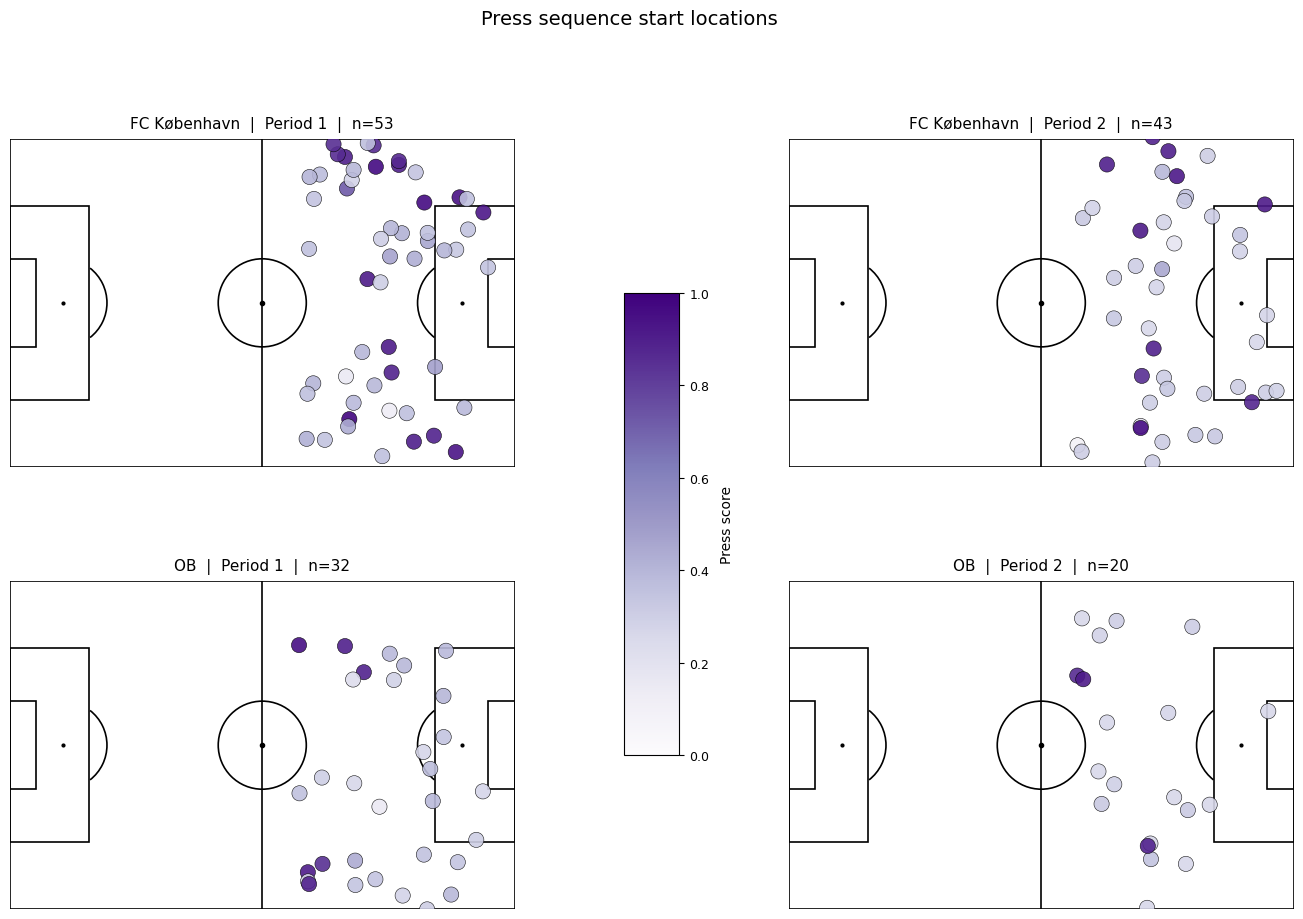

Saved to C:\SDU Courses\Sem 4\Thesis\Viz\press_start_locations.png


In [30]:
# ======================================================
# VISUALIZATION 1 — PRESS SEQUENCE START LOCATIONS
# ======================================================

def draw_pitch(ax, pitch_length, pitch_width, line_color="black", bg_color="white"):
    ax.set_facecolor(bg_color)
    ax.set_xlim(0, pitch_length)
    ax.set_ylim(0, pitch_width)
    ax.set_aspect("equal")
    ax.axis("off")

    lw = 1.2
    hw = pitch_width / 2
    hl = pitch_length / 2

    rect = patches.Rectangle((0, 0), pitch_length, pitch_width,
                               linewidth=lw, edgecolor=line_color, facecolor="none")
    ax.add_patch(rect)
    ax.plot([hl, hl], [0, pitch_width], color=line_color, linewidth=lw)

    centre = plt.Circle((hl, hw), 9.15, color=line_color, fill=False, linewidth=lw)
    ax.add_patch(centre)
    ax.plot(hl, hw, "o", color=line_color, markersize=3)

    for x_base, sign in [(0, 1), (pitch_length, -1)]:
        ax.add_patch(patches.Rectangle(
            (x_base, hw - 20.16), sign * 16.5, 40.32,
            linewidth=lw, edgecolor=line_color, facecolor="none"))
        ax.add_patch(patches.Rectangle(
            (x_base, hw - 9.16), sign * 5.5, 18.32,
            linewidth=lw, edgecolor=line_color, facecolor="none"))
        penalty_x = x_base + sign * 11
        ax.plot(penalty_x, hw, "o", color=line_color, markersize=2)
        arc = patches.Arc((penalty_x, hw), 18.3, 18.3,
                           angle=0,
                           theta1=308 if sign == 1 else 128,
                           theta2=52  if sign == 1 else 232,
                           color=line_color, linewidth=lw)
        ax.add_patch(arc)

    for x_base, sign in [(0, -1), (pitch_length, 1)]:
        ax.add_patch(patches.Rectangle(
            (x_base, hw - 3.66), sign * 2.4, 7.32,
            linewidth=lw, edgecolor=line_color, facecolor="none"))


def get_pressing_team_from_frame(frame, carrier_id):
    if carrier_id is None:
        return None
    carrier_team = get_team_of_player(carrier_id, frame)
    return "away" if carrier_team == "home" else "home"


def normalize_coords(ball_x, ball_y, pressing_team, period, pitch_length, pitch_width):
    period_data = next(
        (p for p in all_metadata[current_match]["periods"] if p["number"] == period),
        None
    )
    home_att_positive = period_data.get("homeAttPositive", False) if period_data else (period == 2)

    if pressing_team == "home":
        att_positive = home_att_positive
    else:
        att_positive = not home_att_positive

    x = ball_x + pitch_length / 2
    y = ball_y + pitch_width / 2

    if not att_positive:
        x = pitch_length - x
        y = pitch_width - y

    return x, y


# --- BUILD PLOT DATA ---
pitch_length = PITCH_LENGTH
pitch_width  = PITCH_WIDTH

plot_data = {("home", 1): [], ("home", 2): [], ("away", 1): [], ("away", 2): []}

for _, seq in press_sequences_df.iterrows():
    start_f = int(seq["start_frame"])
    period  = int(seq["period"])
    score   = seq["press_score"]

    frame   = tracking_df.iloc[start_f]
    ball_xy = frame["ball_xy"]
    carrier = frame["ball_carrier"]

    if ball_xy is None:
        continue

    ball_x, ball_y = ball_xy[0], ball_xy[1]

    if carrier is None:
        next_c = frame.get("next_carrier", None)
        if next_c is None:
            continue
        carrier = next_c

    pressing_team = get_pressing_team_from_frame(frame, carrier)
    if pressing_team is None:
        continue

    nx, ny = normalize_coords(ball_x, ball_y, pressing_team, period, pitch_length, pitch_width)
    plot_data[(pressing_team, period)].append((nx, ny, score))


# --- COLORMAP ---
cmap = cm.Purples
norm = mcolors.Normalize(vmin=0, vmax=1)

team_labels = {"home": "FC København", "away": "OB"}

# --- FIGURE LAYOUT ---
fig = plt.figure(figsize=(18, 10))
fig.patch.set_facecolor("white")

gs = fig.add_gridspec(
    2, 3,
    width_ratios=[10, 1.5, 10],
    wspace=0.08,
    hspace=0.35
)

subplot_positions = {
    ("home", 1): (0, 0),
    ("home", 2): (0, 2),
    ("away", 1): (1, 0),
    ("away", 2): (1, 2),
}

axes = {}
for key, (row, col) in subplot_positions.items():
    axes[key] = fig.add_subplot(gs[row, col])

# --- DRAW PITCHES ---
for (team, period), ax in axes.items():
    draw_pitch(ax, pitch_length, pitch_width, line_color="black", bg_color="white")

    data = plot_data[(team, period)]

    if data:
        xs     = [d[0] for d in data]
        ys     = [d[1] for d in data]
        scores = [d[2] for d in data]
        colors = [cmap(norm(s)) for s in scores]

        ax.scatter(xs, ys, c=colors, s=120, zorder=5,
                   edgecolors="black", linewidths=0.4, alpha=0.9)

    n = len(data)
    ax.set_title(f"{team_labels[team]}  |  Period {period}  |  n={n}",
                 color="black", fontsize=11, pad=8)

# --- COLORBAR IN MIDDLE COLUMN ---
cbar_ax    = fig.add_subplot(gs[:, 1])
cbar_ax.axis("off")
cbar_inner = cbar_ax.inset_axes([0.2, 0.2, 0.6, 0.6])
cb = mcolorbar.ColorbarBase(cbar_inner, cmap=cmap, norm=norm, orientation="vertical")
cb.set_label("Press score", fontsize=10, labelpad=8)
cb.ax.yaxis.set_tick_params(labelsize=9)

plt.suptitle("Press sequence start locations", fontsize=14, color="black", y=1.01)

save_path = r"C:\SDU Courses\Sem 4\Thesis\Viz\press_start_locations.png"
plt.savefig(save_path, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved to {save_path}")

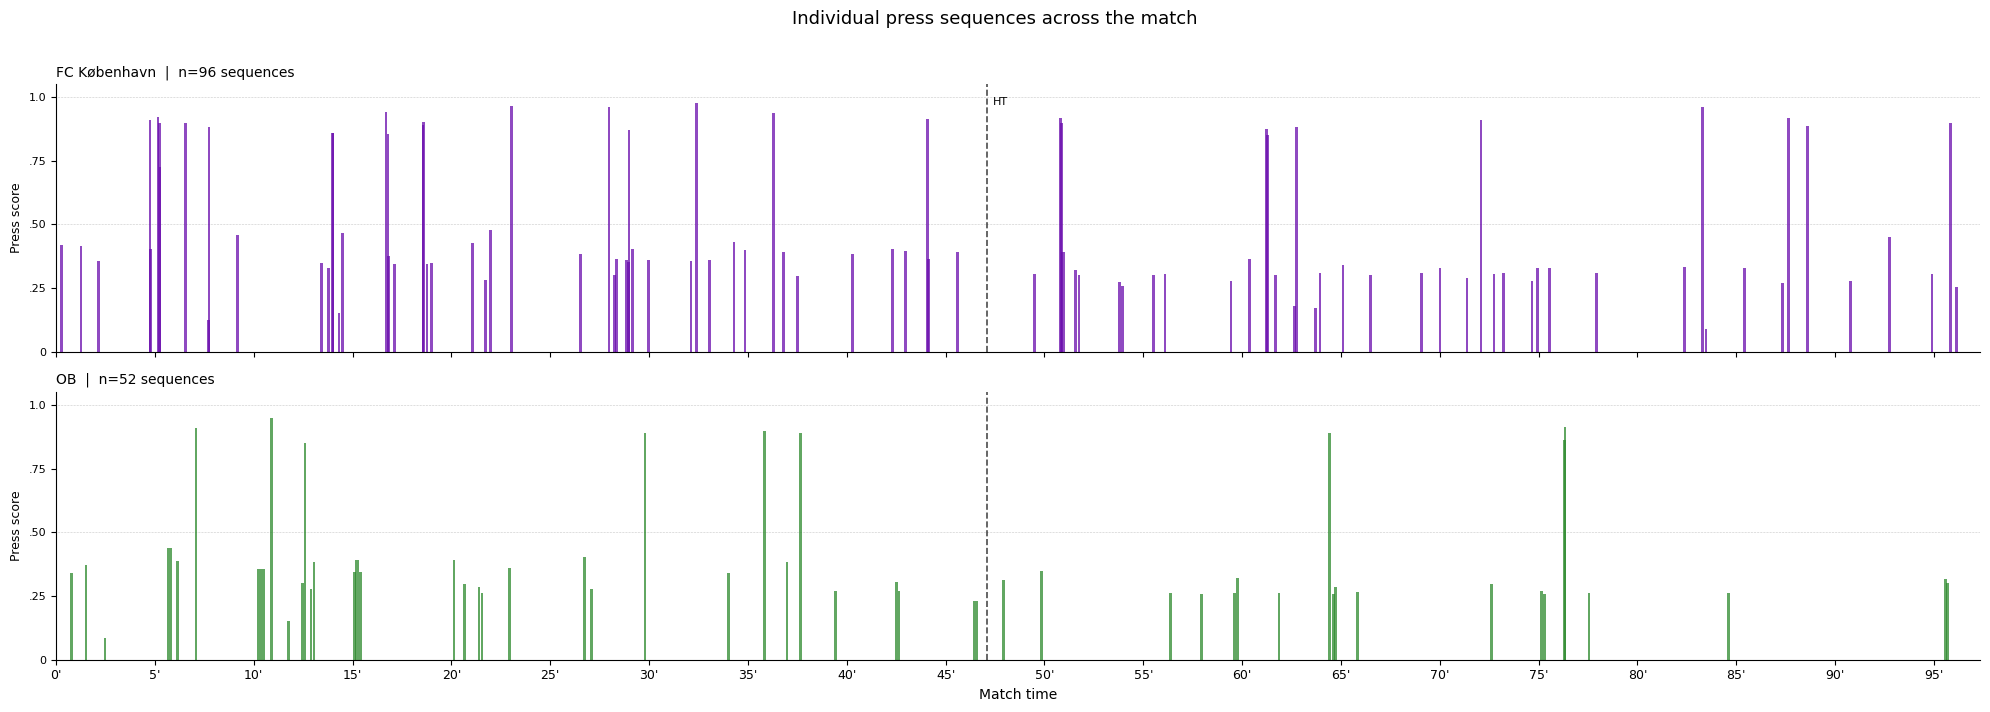

Saved to C:\SDU Courses\Sem 4\Thesis\Viz\press_timeline_individual.png


In [31]:
# ======================================================
# VISUALIZATION 2A — INDIVIDUAL PRESS SEQUENCES TIMELINE
# ======================================================

# --- SETUP ---
team_colors     = {"home": "#6a0dad", "away": "#2d8a2d"}
team_labels_map = {"home": "FC København", "away": "OB"}

period1_frames   = tracking_df[tracking_df["period"] == 1]
period2_frames   = tracking_df[tracking_df["period"] == 2]
period1_duration = period1_frames["gameClock"].max()
period2_duration = period2_frames["gameClock"].max()
total_duration   = period1_duration + period2_duration
ht_marker        = period1_duration

def to_cumulative(time_sec, period):
    return time_sec if period == 1 else period1_duration + time_sec

if "pressing_team" not in press_sequences_df.columns:
    def get_pressing_team(seq):
        start_f = int(seq["start_frame"])
        frame   = tracking_df.iloc[start_f]
        carrier = frame["ball_carrier"]
        if carrier is None:
            carrier = frame.get("next_carrier", None)
        if carrier is None:
            return None
        carrier_team = get_team_of_player(carrier, frame)
        return "away" if carrier_team == "home" else "home"
    press_sequences_df["pressing_team"] = press_sequences_df.apply(
        get_pressing_team, axis=1
    )

def fmt_minutes(x, pos):
    return f"{int(x // 60)}'"

# --- FIGURE ---
fig, axes = plt.subplots(2, 1, figsize=(20, 7), sharex=True)
fig.patch.set_facecolor("white")

for row, team in enumerate(["home", "away"]):
    ax    = axes[row]
    color = team_colors[team]

    ax.set_facecolor("white")
    ax.set_xlim(0, total_duration)
    ax.set_ylim(0, 1.05)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(["0", ".25", ".50", ".75", "1.0"],
                       fontsize=8, color="black")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("black")
    ax.spines["bottom"].set_color("black")
    ax.tick_params(axis="y", colors="black")

    team_seqs = []
    for _, seq in press_sequences_df.iterrows():
        if seq["pressing_team"] != team:
            continue

        period  = int(seq["period"])
        start_t = to_cumulative(seq["start_time"], period)
        end_t   = to_cumulative(seq["end_time"],   period)
        score   = seq["press_score"]
        width   = max(end_t - start_t, 8.0)
        height  = max(score, 0.04)

        rect = patches.Rectangle(
            (start_t, 0), width, height,
            linewidth=0.0, facecolor=color, alpha=0.75
        )
        ax.add_patch(rect)
        team_seqs.append(seq)

    for y in [0.5, 1.0]:
        ax.axhline(y=y, color="black", linewidth=0.4,
                   linestyle=":", alpha=0.4, zorder=0)

    ax.axvline(x=ht_marker, color="black", linewidth=1.2,
               linestyle="--", alpha=0.7, zorder=5)

    if row == 0:
        ax.text(ht_marker + 20, 1.0, "HT",
                color="black", fontsize=8, va="top", ha="left")

    ax.set_ylabel("Press score", fontsize=9, color="black")
    ax.set_title(f"{team_labels_map[team]}  |  n={len(team_seqs)} sequences",
                 fontsize=10, color="black", pad=6, loc="left")

axes[-1].set_xlabel("Match time", fontsize=10, color="black")
axes[-1].xaxis.set_major_formatter(FuncFormatter(fmt_minutes))
axes[-1].xaxis.set_major_locator(plt.MultipleLocator(300))
axes[-1].tick_params(axis="x", colors="black", labelsize=9)

fig.suptitle("Individual press sequences across the match",
             fontsize=13, color="black", y=1.01)
plt.tight_layout()

save_path = r"C:\SDU Courses\Sem 4\Thesis\Viz\press_timeline_individual.png"
plt.savefig(save_path, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved to {save_path}")

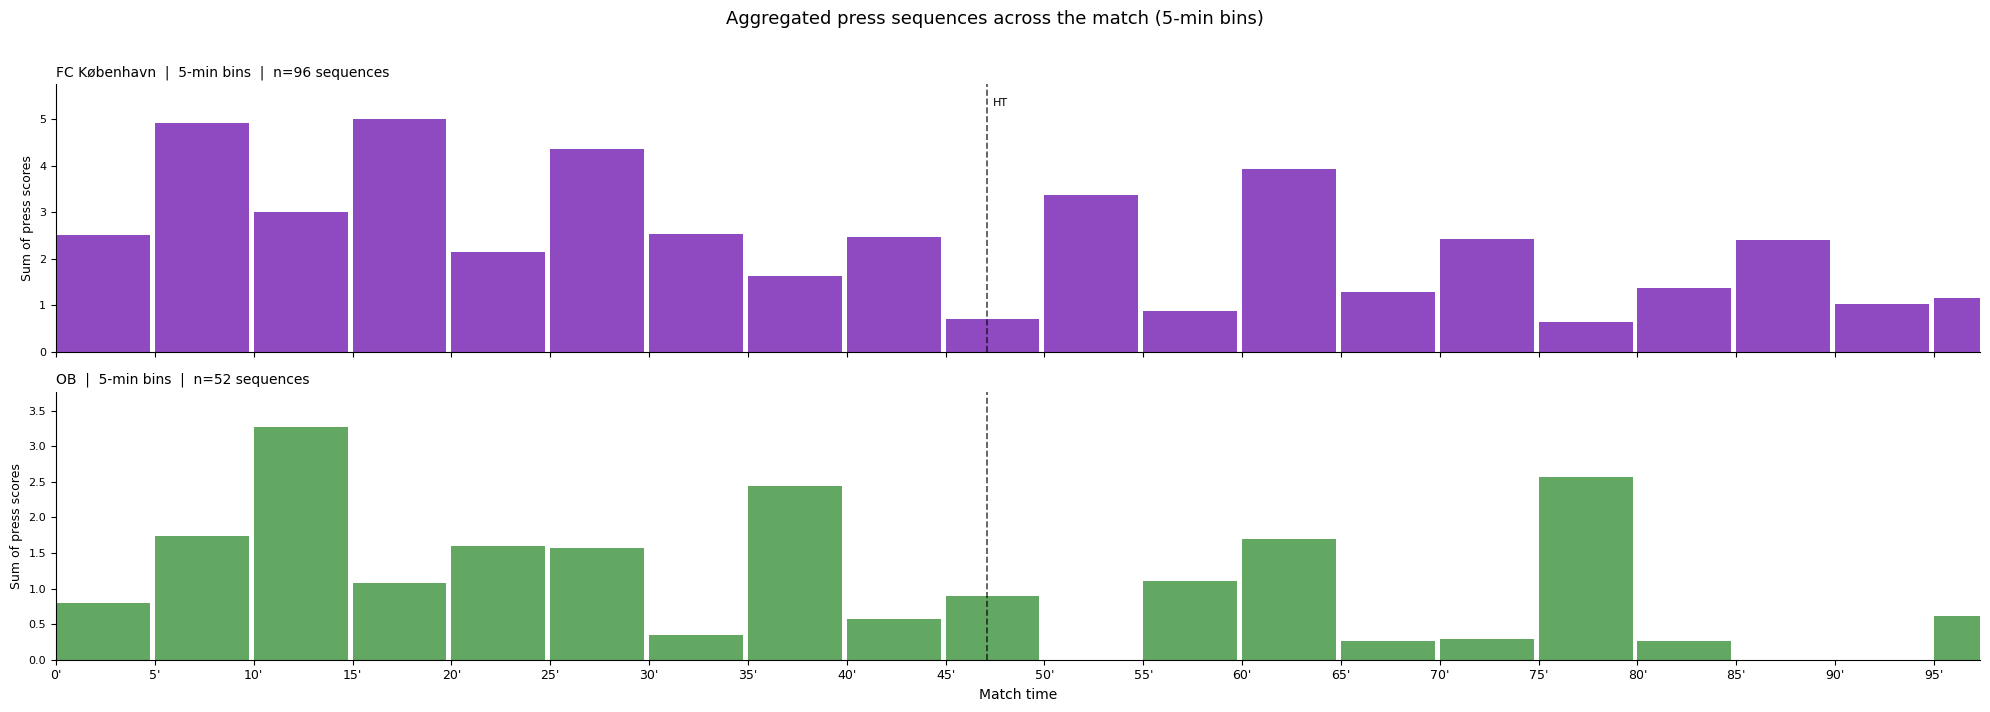

Saved to C:\SDU Courses\Sem 4\Thesis\Viz\press_timeline_aggregated.png


In [32]:
# ======================================================
# VISUALIZATION 2B — AGGREGATED PRESS SEQUENCES TIMELINE
# ======================================================

BIN_SIZE  = 300  # seconds
bin_edges = np.arange(0, total_duration + BIN_SIZE, BIN_SIZE)

if "pressing_team" not in press_sequences_df.columns:
    def get_pressing_team(seq):
        start_f = int(seq["start_frame"])
        frame   = tracking_df.iloc[start_f]
        carrier = frame["ball_carrier"]
        if carrier is None:
            carrier = frame.get("next_carrier", None)
        if carrier is None:
            return None
        carrier_team = get_team_of_player(carrier, frame)
        return "away" if carrier_team == "home" else "home"
    press_sequences_df["pressing_team"] = press_sequences_df.apply(
        get_pressing_team, axis=1
    )

fig, axes = plt.subplots(2, 1, figsize=(20, 7), sharex=True)
fig.patch.set_facecolor("white")

for row, team in enumerate(["home", "away"]):
    ax    = axes[row]
    color = team_colors[team]

    team_seqs = []
    for _, seq in press_sequences_df.iterrows():
        if seq["pressing_team"] != team:
            continue

        period  = int(seq["period"])
        start_t = to_cumulative(seq["start_time"], period)
        score   = seq["press_score"]
        team_seqs.append({"start_t": start_t, "score": score})

    bin_sums = np.zeros(len(bin_edges) - 1)
    for s in team_seqs:
        bin_idx = np.clip(
            np.searchsorted(bin_edges, s["start_t"], side="right") - 1,
            0, len(bin_sums) - 1
        )
        bin_sums[bin_idx] += s["score"]

    bar_x      = bin_edges[:-1]
    bar_widths = np.diff(bin_edges)

    ax.set_facecolor("white")
    ax.set_xlim(0, total_duration)
    ax.set_ylim(0, max(bin_sums.max() * 1.15, 1.0))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("black")
    ax.spines["bottom"].set_color("black")
    ax.tick_params(axis="y", colors="black", labelsize=8)

    ax.bar(bar_x, bin_sums, width=bar_widths * 0.95,
       align="edge", color=color, alpha=0.75, linewidth=0.0)

    ax.axvline(x=ht_marker, color="black", linewidth=1.2,
               linestyle="--", alpha=0.7, zorder=5)

    if row == 0:
        ax.text(ht_marker + 20, ax.get_ylim()[1] * 0.95, "HT",
                color="black", fontsize=8, va="top", ha="left")

    ax.set_ylabel("Sum of press scores", fontsize=9, color="black")
    ax.set_title(f"{team_labels_map[team]}  |  {BIN_SIZE//60}-min bins  |  n={len(team_seqs)} sequences",
                 fontsize=10, color="black", pad=6, loc="left")

axes[-1].set_xlabel("Match time", fontsize=10, color="black")
axes[-1].xaxis.set_major_formatter(FuncFormatter(fmt_minutes))
axes[-1].xaxis.set_major_locator(plt.MultipleLocator(300))
axes[-1].tick_params(axis="x", colors="black", labelsize=9)

fig.suptitle(f"Aggregated press sequences across the match ({BIN_SIZE//60}-min bins)",
             fontsize=13, color="black", y=1.01)
plt.tight_layout()

save_path = r"C:\SDU Courses\Sem 4\Thesis\Viz\press_timeline_aggregated.png"
plt.savefig(save_path, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved to {save_path}")

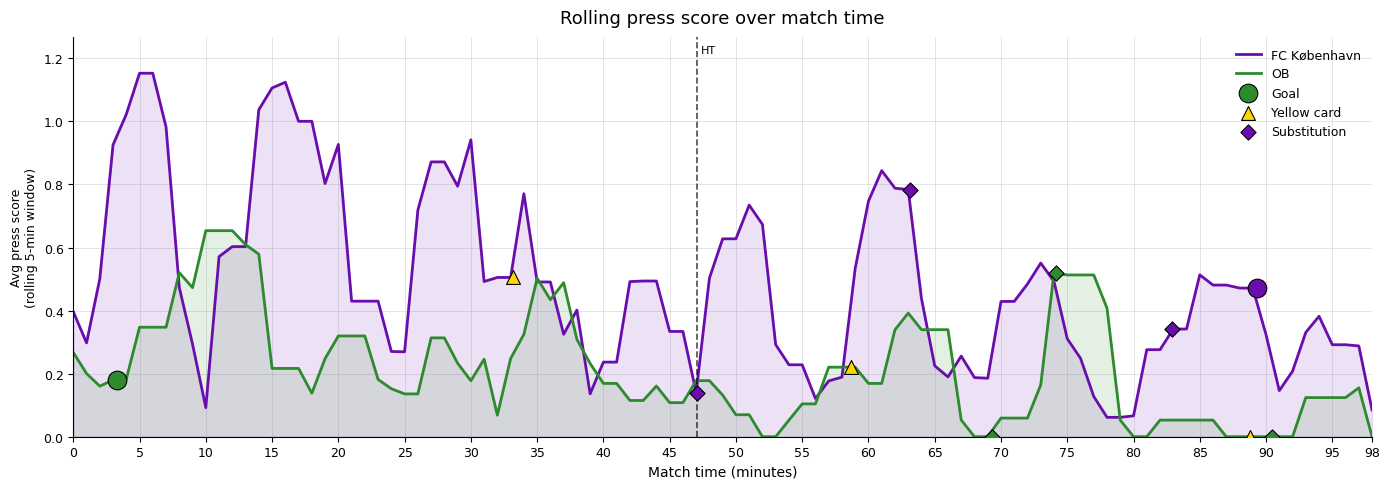

Saved to C:\SDU Courses\Sem 4\Thesis\Viz\press_score_over_time.png


In [33]:
# ======================================================
# VISUALIZATION 3 — ROLLING PRESS SCORE OVER TIME
# ======================================================

# --- SETUP ---
team_colors     = {"home": "#6a0dad", "away": "#2d8a2d"}
team_labels_map = {"home": "FC København", "away": "OB"}
team_id_map     = {"545": "away", "569": "home"}

if "pressing_team" not in press_sequences_df.columns:
    def get_pressing_team(seq):
        start_f = int(seq["start_frame"])
        frame   = tracking_df.iloc[start_f]
        carrier = frame["ball_carrier"]
        if carrier is None:
            carrier = frame.get("next_carrier", None)
        if carrier is None:
            return None
        carrier_team = get_team_of_player(carrier, frame)
        return "away" if carrier_team == "home" else "home"
    press_sequences_df["pressing_team"] = press_sequences_df.apply(
        get_pressing_team, axis=1
    )

period1_frames   = tracking_df[tracking_df["period"] == 1]
period2_frames   = tracking_df[tracking_df["period"] == 2]
period1_duration = period1_frames["gameClock"].max()
period2_duration = period2_frames["gameClock"].max()
total_duration   = period1_duration + period2_duration
ht_marker        = period1_duration

PERIOD1_EVENT_DURATION = 45 * 60

def to_cumulative(time_sec, period):
    return time_sec if period == 1 else period1_duration + time_sec

def event_to_cumulative(event_time_sec, period_id):
    if period_id == 1:
        return event_time_sec
    else:
        return period1_duration + (event_time_sec - PERIOD1_EVENT_DURATION)

# --- BUILD PER-MINUTE TIME SERIES PER TEAM ---
ROLLING_WINDOW = 5   # minutes

full_minutes = list(range(0, int(total_duration // 60) + 2))

team_series = {}

for team in ["home", "away"]:
    team_df = press_sequences_df[
        press_sequences_df["pressing_team"] == team
    ].copy()

    team_df["cum_start"] = team_df.apply(
        lambda r: to_cumulative(r["start_time"], int(r["period"])), axis=1
    )
    team_df["minute_bin"] = (team_df["cum_start"] // 60).astype(int)

    score_per_min = (
        team_df.groupby("minute_bin")["press_score"]
        .sum()
        .reindex(full_minutes, fill_value=0)
        .reset_index(drop=True)
    )

    smoothed = (
        score_per_min
        .rolling(ROLLING_WINDOW, center=True, min_periods=1)
        .mean()
    )

    team_series[team] = {
        "minutes":  np.array(full_minutes),
        "smoothed": smoothed.values
    }

def get_smoothed_at_minute(team, minute):
    minutes  = team_series[team]["minutes"]
    smoothed = team_series[team]["smoothed"]
    idx      = np.argmin(np.abs(minutes - minute))
    return float(smoothed[idx])

# --- MARKER EVENTS ---
marker_events_df = events_df[
    events_df["event_name"].isin(["Goal", "Card", "Player off"])
].copy()

marker_events_df["cum_time"] = marker_events_df.apply(
    lambda r: event_to_cumulative(r["event_time_sec"], r["period_id"]), axis=1
)
marker_events_df["cum_min"] = marker_events_df["cum_time"] / 60
marker_events_df["team"]    = marker_events_df["team_id"].map(team_id_map)

goals = marker_events_df[marker_events_df["event_name"] == "Goal"]
cards = marker_events_df[marker_events_df["event_name"] == "Card"]
subs  = marker_events_df[marker_events_df["event_name"] == "Player off"]

# --- PLOT ---
fig, ax = plt.subplots(figsize=(14, 5))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

for team in ["home", "away"]:
    color   = team_colors[team]
    minutes = team_series[team]["minutes"]
    smooth  = team_series[team]["smoothed"]

    ax.plot(
        minutes, smooth,
        linewidth=2,
        color=color,
        label=team_labels_map[team]
    )

    ax.fill_between(
        minutes, smooth,
        alpha=0.12,
        color=color
    )

# --- Y AXIS RANGE ---
y_max = max(
    team_series["home"]["smoothed"].max(),
    team_series["away"]["smoothed"].max()
) * 1.1

ax.set_ylim(0, y_max)

# --- GOALS ---
first_goal = True
for _, goal in goals.iterrows():
    team   = goal["team"]
    minute = goal["cum_min"]
    y      = get_smoothed_at_minute(team, minute)
    color  = team_colors.get(team, "black")

    ax.scatter(
        minute, y,
        marker="o",
        s=180,
        color=color,
        edgecolor="black",
        linewidth=0.8,
        zorder=6,
        label="Goal" if first_goal else None
    )
    first_goal = False

# --- CARDS ---
first_yellow = True
first_red    = True
for _, card in cards.iterrows():
    team   = card["team"]
    minute = card["cum_min"]
    y      = get_smoothed_at_minute(team, minute)
    is_red = card["card_color"] == "red"
    col    = "#cc0000" if is_red else "#FFD700"

    ax.scatter(
        minute, y,
        marker="^",
        s=100,
        color=col,
        edgecolor="black",
        linewidth=0.8,
        zorder=6,
        label=("Red card" if is_red else "Yellow card") if (first_red if is_red else first_yellow) else None
    )
    if is_red:
        first_red = False
    else:
        first_yellow = False

# --- SUBSTITUTIONS ---
first_sub = True
seen_sub  = set()

for _, sub in subs.iterrows():
    team   = sub["team"]
    minute = sub["cum_min"]
    key    = (int(minute), team)

    if key in seen_sub:
        continue
    seen_sub.add(key)

    y     = get_smoothed_at_minute(team, minute)
    color = team_colors.get(team, "grey")

    ax.scatter(
        minute, y,
        marker="D",
        s=60,
        color=color,
        edgecolor="black",
        linewidth=0.8,
        zorder=6,
        label="Substitution" if first_sub else None
    )
    first_sub = False

# --- HALFTIME LINE ---
ht_min = ht_marker / 60
ax.axvline(x=ht_min, color="black", linewidth=1.2,
           linestyle="--", alpha=0.7, zorder=5)
ax.text(ht_min + 0.3, y_max * 0.98, "HT",
        color="black", fontsize=8, va="top", ha="left")

# --- AXES ---
max_minute = int(total_duration // 60) + 1
ticks      = list(range(0, max_minute + 1, 5))
if max_minute not in ticks:
    ticks.append(max_minute)

ax.set_xticks(ticks)
ax.set_xlim(0, max_minute)

ax.set_xlabel("Match time (minutes)", fontsize=10, color="black")
ax.set_ylabel(f"Avg press score\n(rolling {ROLLING_WINDOW}-min window)",
              fontsize=9, color="black")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("black")
ax.spines["bottom"].set_color("black")
ax.tick_params(axis="both", colors="black", labelsize=9)
ax.grid(alpha=0.3, color="grey", linewidth=0.5)

ax.legend(fontsize=9, frameon=False, loc="upper right")
ax.set_title("Rolling press score over match time",
             fontsize=13, color="black", pad=10)

plt.tight_layout()

save_path = r"C:\SDU Courses\Sem 4\Thesis\Viz\press_score_over_time.png"
plt.savefig(save_path, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved to {save_path}")

In [34]:
# ======================================================
# VISUALIZATION 4 — ANIMATED SEQUENCE VIEW (GIF)
# ======================================================

%matplotlib inline

# --- SELECT SEQUENCE ---
SEQ_INDEX = 3   # ← change this to animate a different sequence

seq     = press_sequences_df.iloc[SEQ_INDEX]
start_f = int(seq["start_frame"])
end_f   = int(seq["end_frame"])
period  = int(seq["period"])
score   = seq["press_score"]
outcome = seq["outcome"]
term    = seq["term_reason"]

print(f"Animating sequence {SEQ_INDEX}")
print(f"  Period:    {period}")
print(f"  Time:      {seq['start_time_clock']} → {seq['end_time_clock']}")
print(f"  Duration:  {seq['duration_sec']:.1f}s")
print(f"  Score:     {score:.3f}")
print(f"  Outcome:   {outcome}")
print(f"  End:       {term}")
print(f"  Frames:    {end_f - start_f + 1}")

frames = list(range(start_f, end_f + 1))

# --- PITCH SETUP ---
pitch_length = PITCH_LENGTH
pitch_width  = PITCH_WIDTH

fig, ax = plt.subplots(figsize=(14, 9))
fig.patch.set_facecolor("white")

def setup_pitch(ax):
    ax.set_facecolor("#f5f5f5")
    ax.set_xlim(-pitch_length / 2 - 3, pitch_length / 2 + 3)
    ax.set_ylim(-pitch_width  / 2 - 3, pitch_width  / 2 + 3)
    ax.set_aspect("equal")
    ax.axis("off")

    lw = 1.0
    hw = pitch_width  / 2
    hl = pitch_length / 2

    rect = patches.Rectangle((-hl, -hw), pitch_length, pitch_width,
                               linewidth=lw, edgecolor="black", facecolor="none")
    ax.add_patch(rect)
    ax.plot([0, 0], [-hw, hw], color="black", linewidth=lw)

    centre = plt.Circle((0, 0), 9.15, color="black", fill=False, linewidth=lw)
    ax.add_patch(centre)
    ax.plot(0, 0, "o", color="black", markersize=3)

    for x_base, sign in [(-hl, 1), (hl, -1)]:
        ax.add_patch(patches.Rectangle(
            (x_base, -20.16), sign * 16.5, 40.32,
            linewidth=lw, edgecolor="black", facecolor="none"))
        ax.add_patch(patches.Rectangle(
            (x_base, -9.16), sign * 5.5, 18.32,
            linewidth=lw, edgecolor="black", facecolor="none"))
        penalty_x = x_base + sign * 11
        ax.plot(penalty_x, 0, "o", color="black", markersize=2)
        arc = patches.Arc((penalty_x, 0), 18.3, 18.3,
                           angle=0,
                           theta1=308 if sign == 1 else 128,
                           theta2=52  if sign == 1 else 232,
                           color="black", linewidth=lw)
        ax.add_patch(arc)

    for x_base, sign in [(-hl, -1), (hl, 1)]:
        ax.add_patch(patches.Rectangle(
            (x_base, -3.66), sign * 2.4, 7.32,
            linewidth=lw, edgecolor="black", facecolor="none"))

setup_pitch(ax)

# --- COLORS ---
COLOR_HOME_DIM = "#aab4c8"
COLOR_AWAY_DIM = "#c8aab4"
COLOR_CARRIER  = "#f5a800"
COLOR_PRESSER  = "#cc00cc"
COLOR_BALL     = "black"
SIZE_PLAYER    = 120
SIZE_PRESSER   = 180
SIZE_CARRIER   = 180
SIZE_BALL      = 80

# --- SCATTER OBJECTS ---
scat_home    = ax.scatter([], [], s=SIZE_PLAYER,  c=COLOR_HOME_DIM,
                           zorder=3, alpha=0.5, linewidths=0)
scat_away    = ax.scatter([], [], s=SIZE_PLAYER,  c=COLOR_AWAY_DIM,
                           zorder=3, alpha=0.5, linewidths=0)
scat_carrier = ax.scatter([], [], s=SIZE_CARRIER, c=COLOR_CARRIER,
                           zorder=5, alpha=1.0, linewidths=0.8,
                           edgecolors="black")
scat_presser = ax.scatter([], [], s=SIZE_PRESSER, c=COLOR_PRESSER,
                           zorder=5, alpha=1.0, linewidths=0.8,
                           edgecolors="black")
scat_ball    = ax.scatter([], [], s=SIZE_BALL,    c=COLOR_BALL,
                           zorder=6, alpha=1.0, linewidths=0)

press_line, = ax.plot([], [], color=COLOR_PRESSER, linewidth=1.2,
                      linestyle="--", alpha=0.6, zorder=4)

time_text = ax.text(
    0.01, 0.97, "", transform=ax.transAxes,
    fontsize=10, va="top", ha="left", color="black"
)
ax.text(
    0.5, 1.01,
    f"Seq {SEQ_INDEX}  |  {seq['start_time_clock']}–{seq['end_time_clock']}"
    f"  |  score: {score:.2f}  |  outcome: {outcome}",
    transform=ax.transAxes,
    fontsize=9, va="bottom", ha="center", color="black"
)

legend_items = [
    patches.Patch(facecolor=COLOR_HOME_DIM, label="Home players"),
    patches.Patch(facecolor=COLOR_AWAY_DIM, label="Away players"),
    patches.Patch(facecolor=COLOR_CARRIER,  label="Ball carrier"),
    patches.Patch(facecolor=COLOR_PRESSER,  label="Pressing defender"),
    patches.Patch(facecolor=COLOR_BALL,     label="Ball"),
]
ax.legend(handles=legend_items, loc="lower right", fontsize=8,
          framealpha=0.8, edgecolor="none")


def update(frame_idx):
    frame      = tracking_df.iloc[frame_idx]
    carrier_id = frame["ball_carrier"]
    presser_id = frame["presser_id"]
    ball_xyz   = frame["ball.xyz"]

    home_xy, away_xy       = [], []
    carrier_xy, presser_xy = [], []

    for p in frame["homePlayers"]:
        pid = p["optaId"]
        pos = p.get("xyz", None)
        if pos is None:
            continue
        x, y = pos[0], pos[1]
        if pid == presser_id:
            presser_xy.append((x, y))
        elif pid == carrier_id:
            carrier_xy.append((x, y))
        else:
            home_xy.append((x, y))

    for p in frame["awayPlayers"]:
        pid = p["optaId"]
        pos = p.get("xyz", None)
        if pos is None:
            continue
        x, y = pos[0], pos[1]
        if pid == presser_id:
            presser_xy.append((x, y))
        elif pid == carrier_id:
            carrier_xy.append((x, y))
        else:
            away_xy.append((x, y))

    def set_scatter(scat, pts):
        if pts:
            scat.set_offsets(np.array(pts))
        else:
            scat.set_offsets(np.empty((0, 2)))

    set_scatter(scat_home,    home_xy)
    set_scatter(scat_away,    away_xy)
    set_scatter(scat_carrier, carrier_xy)
    set_scatter(scat_presser, presser_xy)

    if isinstance(ball_xyz, (list, tuple)):
        scat_ball.set_offsets(np.array([[ball_xyz[0], ball_xyz[1]]]))
    else:
        scat_ball.set_offsets(np.empty((0, 2)))

    if presser_xy and carrier_xy:
        px, py = presser_xy[0]
        cx, cy = carrier_xy[0]
        press_line.set_data([px, cx], [py, cy])
    else:
        press_line.set_data([], [])

    clock = frame["gameClock"]
    m     = int(clock // 60)
    s     = int(clock % 60)
    time_text.set_text(f"P{period}  {m:02d}:{s:02d}")

    return (scat_home, scat_away, scat_carrier,
            scat_presser, scat_ball, press_line, time_text)


ani = animation.FuncAnimation(
    fig,
    update,
    frames=frames,
    interval=80,
    blit=True,
    repeat=False
)

# --- SAVE AS GIF ---
save_path = rf"C:\SDU Courses\Sem 4\Thesis\Viz\sequence_{SEQ_INDEX}.gif"
print(f"Saving GIF — {len(frames)} frames, this may take a moment...")

ani.save(save_path, writer="pillow", fps=12, dpi=80)
plt.close()

print(f"Saved: {save_path}")

Animating sequence 3
  Period:    1
  Time:      01:27 → 01:30
  Duration:  3.3s
  Score:     0.373
  Outcome:   forced_sideways
  End:       aerial
  Frames:    84
Saving GIF — 84 frames, this may take a moment...
Saved: C:\SDU Courses\Sem 4\Thesis\Viz\sequence_3.gif
